# 2標本検定達のαエラーについて (正規母集団の場合)

Studentのt検定, Welchのt検定, Mann-WhitneyのU検定, Brunner-Munzel検定の正規母集団に関するαエラーを比較する.

* 黒木 玄
* 2026-11-02

In [1]:
# Google Colabと自分のパソコンの両方で使えるようにするための工夫

haskey(ENV, "COLAB_GPU") && (ENV["JULIA_PKG_PRECOMPILE_AUTO"] = "0")
using Pkg

"""すでにPkg.add済みのパッケージのリスト"""
_packages_added = [sort!(readdir(Sys.STDLIB));
    sort!([info.name for (uuid, info) in Pkg.dependencies() if info.is_direct_dep])]

"""_packages_added内にないパッケージをPkg.addする"""
add_pkg_if_not_added_yet(pkg) = if isnothing(Base.find_package(pkg))
    println(stderr, "# $(pkg).jl is not added yet, so let's add it.")
    Pkg.add(pkg)
end

"""expr::Exprからusing内の`.`を含まないモジュール名を抽出"""
function find_using_pkgs(expr::Expr)
    pkgs = String[]
    function traverse(expr::Expr)
        if expr.head == :using
            for arg in expr.args
                if arg.head == :. && length(arg.args) == 1
                    push!(pkgs, string(arg.args[1]))
                elseif arg.head == :(:) && length(arg.args[1].args) == 1
                    push!(pkgs, string(arg.args[1].args[1]))
                end
            end
        else
            for arg in expr.args arg isa Expr && traverse(arg) end
        end
    end
    traverse(expr)
    pkgs
end

"""必要そうなPkg.addを追加するマクロ"""
macro autoadd(expr)
    pkgs = find_using_pkgs(expr)
    :(add_pkg_if_not_added_yet.($(pkgs)); $expr)
end

@autoadd (macro with 1 method)

In [2]:
mynthreads() = Threads.nthreads() + Threads.nthreads(:interactive)
using Random # for rand!

@autoadd using Distributions
# @autoadd using Roots
@autoadd using Plots
default(fmt=:png, titlefontsize=12)

ecdf_(A, x) = count(≤(x), A) / length(A)

ecdf_ (generic function with 1 method)

In [3]:
function tvalue_welch(m, x̄, sx², n, ȳ, sy²; Δμ=0)
    (x̄ - ȳ - Δμ) / √(sx²/m + sy²/n)
end

function tvalue_welch(x, y; Δμ=0)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    tvalue_welch(m, x̄, sx², n, ȳ, sy²; Δμ)
end

function degree_of_freedom_welch(m, sx², n, sy²)
    (sx²/m + sy²/n)^2 / ((sx²/m)^2/(m-1) + (sy²/n)^2/(n-1))
end

function degree_of_freedom_welch(x, y)
    m, sx² = length(x), var(x)
    n, sy² = length(y), var(y)
    degree_of_freedom_welch(m, sx², n, sy²)
end

function pvalue_welch(m, x̄, sx², n, ȳ, sy²; Δμ=0)
    t = tvalue_welch(m, x̄, sx², n, ȳ, sy²; Δμ)
    ν = degree_of_freedom_welch(m, sx², n, sy²)
    2ccdf(TDist(ν), abs(t))
end

function pvalue_welch(x, y; Δμ=0)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    pvalue_welch(m, x̄, sx², n, ȳ, sy²; Δμ)
end

function confint_welch(m, x̄, sx², n, ȳ, sy²; α=0.05)
    ν = degree_of_freedom_welch(m, sx², n, sy²)
    c = quantile(TDist(ν), 1-α/2)
    SEhat = √(sx²/m + sy²/n)
    [x̄-ȳ-c*SEhat, x̄-ȳ+c*SEhat]
end

function confint_welch(x, y; α=0.05)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    confint_welch(m, x̄, sx², n, ȳ, sy²; α)
end

confint_welch (generic function with 2 methods)

In [4]:
s²_student(m, sx², n, sy²) = ((m-1)*sx² + (n-1)*sy²)/(m+n-2)

function tvalue_student(m, x̄, sx², n, ȳ, sy²; Δμ=0)
    s² = s²_student(m, sx², n, sy²)
    (x̄ - ȳ - Δμ) / √(s²*(1/m + 1/n))
end

function tvalue_student(x, y; Δμ=0)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    tvalue_student(m, x̄, sx², n, ȳ, sy²; Δμ)
end

function pvalue_student(m, x̄, sx², n, ȳ, sy²; Δμ=0)
    t = tvalue_student(m, x̄, sx², n, ȳ, sy²; Δμ)
    2ccdf(TDist(m+n-2), abs(t))
end

function pvalue_student(x, y; Δμ=0)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    pvalue_student(m, x̄, sx², n, ȳ, sy²; Δμ)
end

function confint_student(m, x̄, sx², n, ȳ, sy²; α=0.05)
    c = quantile(TDist(m+n-2), 1-α/2)
    s² = s²_student(m, sx², n, sy²)
    SEhat = √(s²*(1/m + 1/n))
    [x̄-ȳ-c*SEhat, x̄-ȳ+c*SEhat]
end

function confint_student(x, y; α=0.05)
    m, x̄, sx² = length(x), mean(x), var(x)
    n, ȳ, sy² = length(y), mean(y), var(y)
    confint_student(m, x̄, sx², n, ȳ, sy²; α)
end

confint_student (generic function with 2 methods)

In [5]:
hodges_lehmann(X, Y) = median(x - y for x in X, y in Y)

winrate(X, Y) = mean((x < y) + (x == y)/2 for x in X, y in Y)

function brunner_munzel_test(X, Y; p=1/2, α=0.05)
    phat = winrate(X, Y)
    m, n = length(X), length(Y)
    sx2 = 1/(m-1) * sum(x -> (mean(y -> (y < x) + (y == x)/2, Y) - (1 - phat))^2, X)
    sy2 = 1/(n-1) * sum(y -> (mean(x -> (x < y) + (x == y)/2, X) - phat)^2, Y)
    sehat = √(sx2/m + sy2/n)
    tvalue = (phat - p)/sehat
    df = (sx2/m + sy2/n)^2 / ((sx2/m)^2/(m-1) + (sy2/n)^2/(n-1))
    pvalue = sehat > 0 ? 2ccdf(TDist(df), abs(tvalue)) : phat ≈ p ? 1.0 : 0.0
    c = sehat > 0 ? cquantile(TDist(df), α/2) : 0.0
    confint_p = (phat - c*sehat, phat + c*sehat)
    (; p, phat, sehat, tvalue, df, pvalue, α, confint_p)
end

pvalue_brunner_munzel(X, Y; p=1/2) = brunner_munzel_test(X, Y; p).pvalue

function _pvalue_brunner_munzel(p, phat, sehat, df)
    tvalue = (phat - p)/sehat
    sehat > 0 ? 2ccdf(TDist(df), abs(tvalue)) : phat ≈ p ? 1.0 : 0.0
end

# function confint_bm_p_roots(X, Y; α=0.05)
#     f(p) = brunner_munzel_test(X, Y; p).pvalue - α
#     find_zeros(f, -1, 2)
# end

function aminamax(X, Y)
    xmin, xmax = extrema(X)
    ymin, ymax = extrema(Y)
    width = max(xmax, ymax) - min(xmin, ymin)
    xmin - ymax - max(0.1, 0.05width), xmax - ymin + max(0.1, 0.05width)
end

# function tieshift(X, Y; p=1/2)
#     f(a) = winrate(X, Y .+ a) - p
#     amin, amax = aminamax(X, Y)
#     find_zero(f, (amin, amax))
# end

# function confint_bm_tieshift(X, Y; α=0.05)
#     f(a) = brunner_munzel_test(X, Y .+ a).pvalue - α
#     amin, amax = aminamax(X, Y)
#     find_zeros(f, amin, amax)
# end

aminamax (generic function with 1 method)

In [6]:
function mann_whitney_u_test(X, Y; correct=true)
    m, n = length(X), length(Y)
    phat = mean((x < y) + (x == y)/2 for x in X, y in Y)
    sehat = √((m+n+1)/(12m*n))
    zvalue = (phat - 1/2)/sehat
    correction = correct/(2m*n*sehat)
    pvalue = 2ccdf(Normal(), max(0, abs(zvalue) - correction))
    (; phat, sehat, zvalue, pvalue)
end

pvalue_mann_whitney_u_test(X, Y; correct=true) = mann_whitney_u_test(X, Y; correct).pvalue

# using HypothesisTests
# X = randn(100)
# Y = randn(100)
# @show pvalue_mann_whitney_u_test(X, Y) pvalue(ApproximateMannWhitneyUTest(X, Y))
# X = randn(10)
# Y = randn(10)
# @show pvalue_mann_whitney_u_test(X, Y) pvalue(ApproximateMannWhitneyUTest(X, Y));

pvalue_mann_whitney_u_test (generic function with 1 method)

In [7]:
function sim_pvalues(;
        distx = Normal(0, 1),
        disty = Normal(0, 1),
        m = 50,
        n = 50,
        L = 10^5,
        np = true
    )
    pval_s = zeros(L)
    pval_w = zeros(L)
    if np
        pval_mw = zeros(L)
        pval_bm = zeros(L)
    else
        pval_mw = zeros(0)
        pval_bm = zeros(0)
    end
    Xtmp = [zeros(m) for _ in 1:mynthreads()]
    Ytmp = [zeros(n) for _ in 1:mynthreads()]
    Threads.@threads :static for i in 1:L
        tid = Threads.threadid()
        X = rand!(distx, Xtmp[tid])
        Y = rand!(disty, Ytmp[tid])
        pval_s[i] = pvalue_student(X, Y)
        pval_w[i] = pvalue_welch(X, Y)
        if np
            pval_mw[i] = pvalue_mann_whitney_u_test(X, Y)
            pval_bm[i] = pvalue_brunner_munzel(X, Y)
        end
    end
    (; pval_s, pval_w, pval_mw, pval_bm)
end

function powers(;
        distx = Normal(0, 1),
        disty = Normal(0, 1),
        m = 50,
        n = 50,
        L = 10^5,
        α = 0.05,
        np = false,
    )
    (; pval_s, pval_w, pval_mw, pval_bm) = sim_pvalues(; distx, disty, m, n, L, np)
    power_s = ecdf_(pval_s, α)
    power_w = ecdf_(pval_w, α)
    if np
        power_mw = ecdf_(pval_mw, α)
        power_bm = ecdf_(pval_bm, α)
    else
        power_mw = NaN
        power_bm = NaN
    end
    (; power_s, power_w, power_mw, power_bm)
end

function plot_powers(;
        Δμ = 0.0,
        σratios = [0.33, 0.5, 0.7, 1.0, 1.4, 2.0, 3.0],
        xticks = (σratios, string.(σratios)),
        xscale = :log10,
        m = 50,
        n = 50,
        L = 10^5,
        α = 0.05,
        np = false,
        μ₁ = 0.0,
        σ₁ = 1.0,
        kwargs...
    )
    powers_s = zeros(length(σratios))
    powers_w = similar(powers_s)
    if np
        powers_mw = similar(powers_s)
        powers_bm = similar(powers_s)
    else
        powers_mw = zeros(0)
        powers_bm = zeros(0)
    end
    for (i, σratio) in enumerate(σratios)
        distx = Normal(0, 1)
        disty = Normal(Δμ, σratio)
        (; power_s, power_w, power_mw, power_bm) = powers(; distx, disty, m, n, L, α, np)
        powers_s[i] = power_s
        powers_w[i] = power_w
        if np
            powers_mw[i] = power_mw
            powers_bm[i] = power_bm
        end
    end
    plot(σratios, powers_s; marker=:o, msc=:auto, label="Student", c=1)
    plot!(σratios, powers_w; marker=:star, msc=:auto, label="Welch", ls=:dash, c=2)
    np && plot!(σratios, powers_mw; marker=:utriangle, msc=:auto, label="MW", ls=:dashdot, c=3)
    np && plot!(σratios, powers_bm; marker=:diamond, msc=:auto, label="BM", ls=:dashdotdot, c=4)
    plot!(; ylim=(-0.03, 1.03))
    plot!(; xticks, yticks=0:0.05:1, xscale)
    yguide = Δμ == 0 ? "α-error rate" : "power"
    plot!(; xguide="s₂/s₁", yguide)
    Δμstr = Δμ == 0 ? "0" : Δμ != 1 ? "$(Δμ)s₁" : "s₁"
    title!("Δμ=$Δμstr,  n₁=$m,  n₂=$n   (sim_iters=$L)")
    plot!(; size=(500, 300))
    plot!(; kwargs...)
end

function plot_α_error_rates(;
        distx = Normal(0, 1),
        disty = Normal(0, 1),
        m = 50,
        n = 50,
        L = 10^6,
        np = true,
        kwargs...
    )
    @show distx disty
    (; pval_s, pval_w, pval_mw, pval_bm) = sim_pvalues(; distx, disty, m, n, L, np)
    plot(identity, 0, 0.1; label="", lw=0.5, c=:black, ls=:dot)
    plot!(α -> ecdf_(pval_s, α), 0, 0.1; label="Student", c=1)
    plot!(α -> ecdf_(pval_w, α), 0, 0.1; label="Welch", c=2, ls=:dash)
    np && plot!(α -> ecdf_(pval_mw, α), 0, 0.1; label="MW", c=3, ls=:dashdot)
    np && plot!(α -> ecdf_(pval_bm, α), 0, 0.1; label="BM", c=4, ls=:dashdotdot)
    plot!(xtick=0:0.01:1, ytick=0:0.01:1)
    plot!(xguide="α", yguide="probability of P-value ≤ α")
    title!("n₁=$m,  n₂=$n   (sim_iters=$L)")
    plot!(; size=(400, 400), titlefontsize=10)
    plot!(; kwargs...)
end

plot_α_error_rates (generic function with 1 method)

  1.259236 seconds (6.43 M allocations: 753.050 MiB, 9.58% gc time, 538.27% compilation time: 4% of which was recompilation)


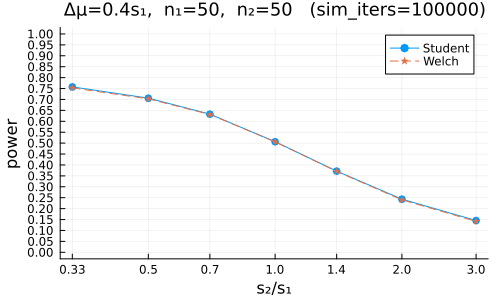

In [8]:
@time plot_powers(; Δμ=0.4)

  0.212268 seconds (4.80 M allocations: 706.263 MiB, 27.14% gc time)


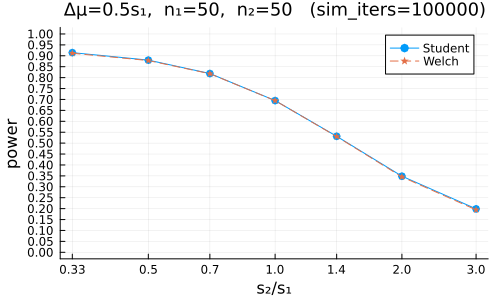

In [9]:
@time plot_powers(; Δμ=0.5)

  2.333354 seconds (24.08 M allocations: 3.076 GiB, 10.38% gc time, 2.83% compilation time)


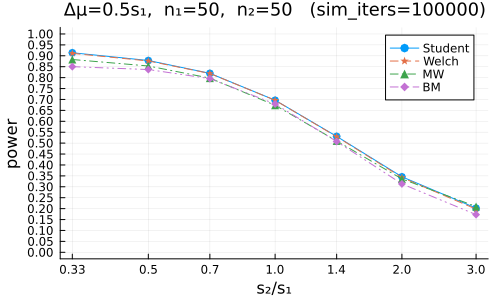

In [10]:
@time plot_powers(; Δμ=0.5, np=true)

  2.356612 seconds (24.08 M allocations: 3.075 GiB, 9.43% gc time)


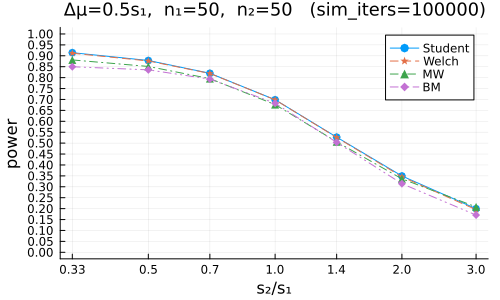

In [11]:
@time plot_powers(; Δμ=0.5, np=true)

 13.450554 seconds (180.70 M allocations: 26.617 GiB, 13.68% gc time, 0.53% compilation time)


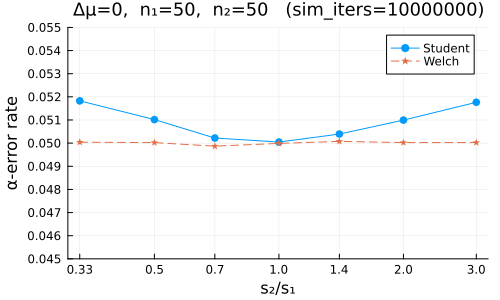

In [12]:
@time plot_powers(; Δμ=0, ylim=(0.045, 0.055), L=10^7, ytick=0:0.001:1)

 23.884901 seconds (196.85 M allocations: 24.528 GiB, 7.11% gc time)


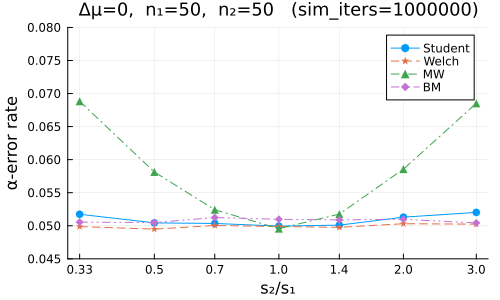

In [13]:
@time plot_powers(; Δμ=0, ylim=(0.045, 0.08), L=10^6, ytick=0:0.005:1, np=true)

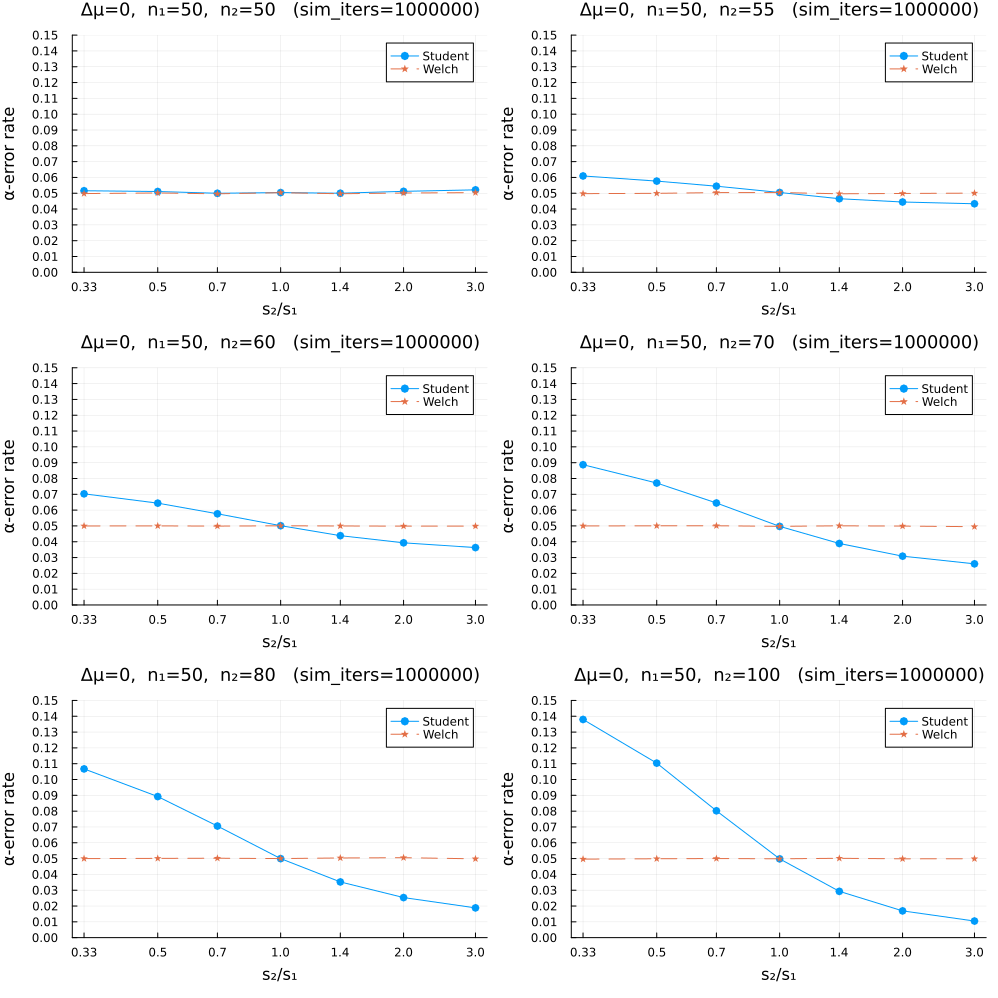

In [14]:
PP = []
for n in (50, 55, 60, 70, 80, 100)
    P = plot_powers(; Δμ=0, m=50, n, ylim=(0.00, 0.15), L=10^6, ytick=0:0.01:1)
    push!(PP, P)
end
plot(PP...; size=(1000, 1000), layout=(3, 2))

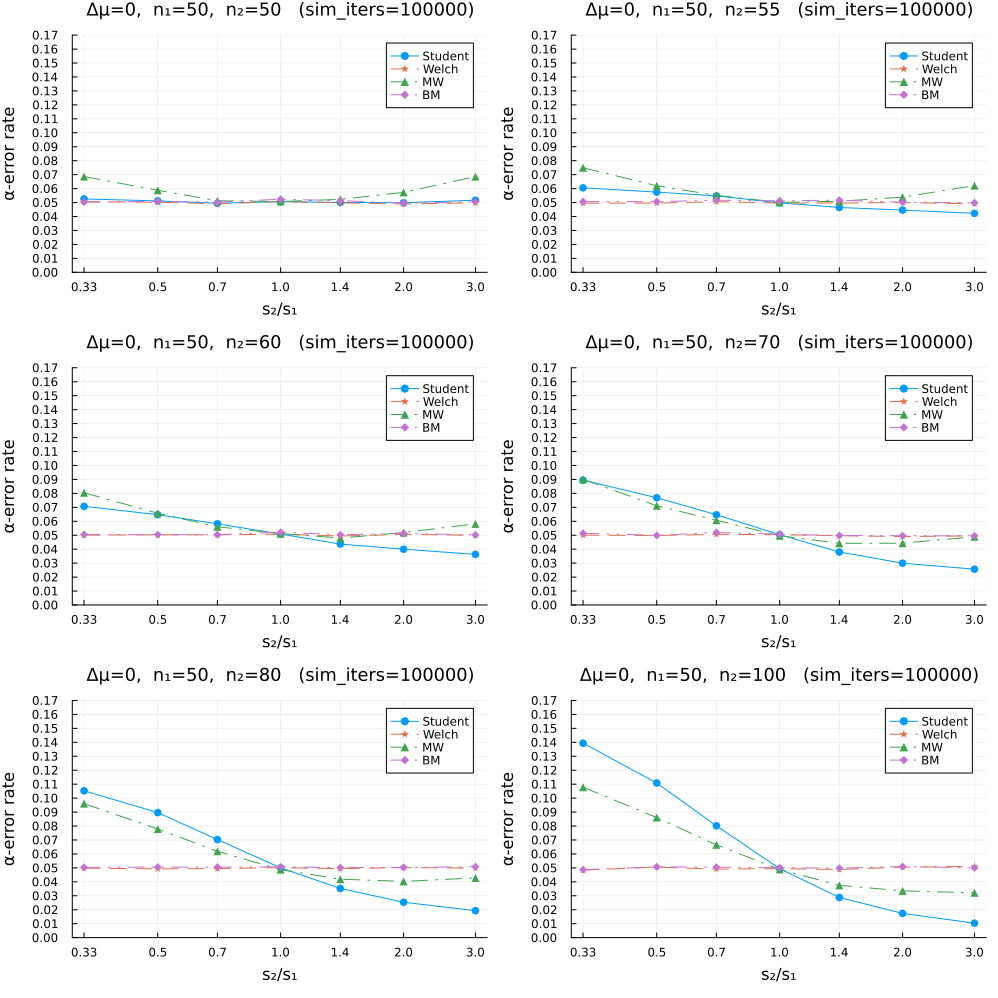

In [15]:
PP = []
for n in (50, 55, 60, 70, 80, 100)
    P = plot_powers(; Δμ=0, m=50, n, ylim=(0.00, 0.17), L=10^5, ytick=0:0.01:1, np=true)
    push!(PP, P)
end
plot(PP...; size=(1000, 1000), layout=(3, 2))

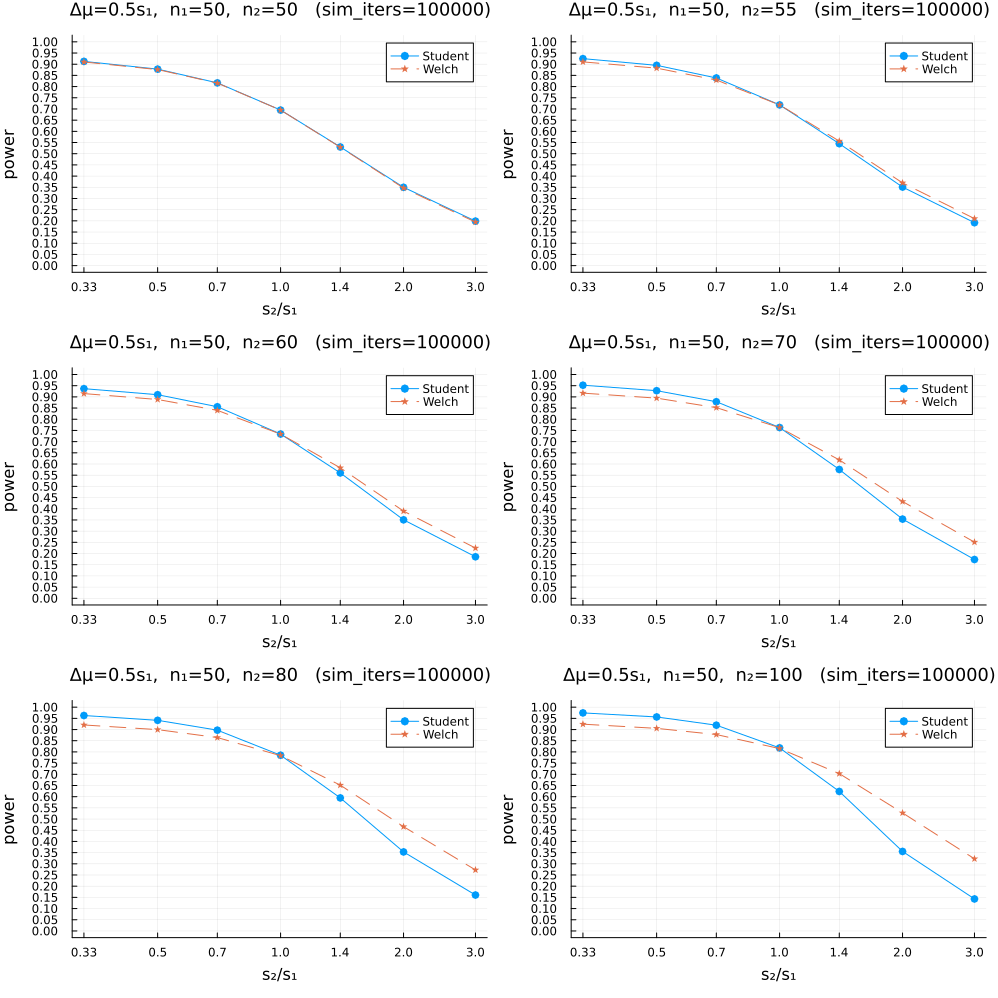

In [16]:
PP = []
for n in (50, 55, 60, 70, 80, 100)
    P = plot_powers(; Δμ=0.5, m=50, n)
    push!(PP, P)
end
plot(PP...; size=(1000, 1000), layout=(3, 2))

 11.236854 seconds (168.93 M allocations: 24.957 GiB, 17.00% gc time)


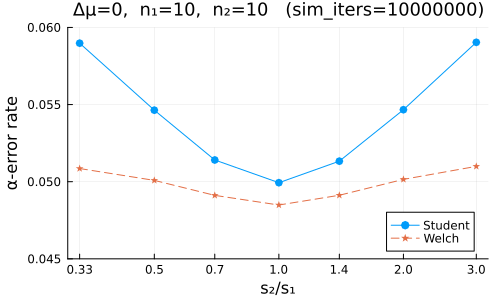

In [17]:
@time plot_powers(; Δμ=0, m=10, n=10, ylim=(0.045, 0.06), L=10^7, ytick=0:0.005:1)

  6.157974 seconds (157.46 M allocations: 18.952 GiB, 20.31% gc time)


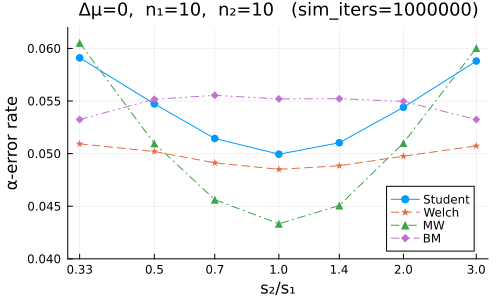

In [18]:
@time plot_powers(; Δμ=0, m=10, n=10, ylim=(0.04, 0.062), L=10^6, ytick=0:0.005:1, np=true)

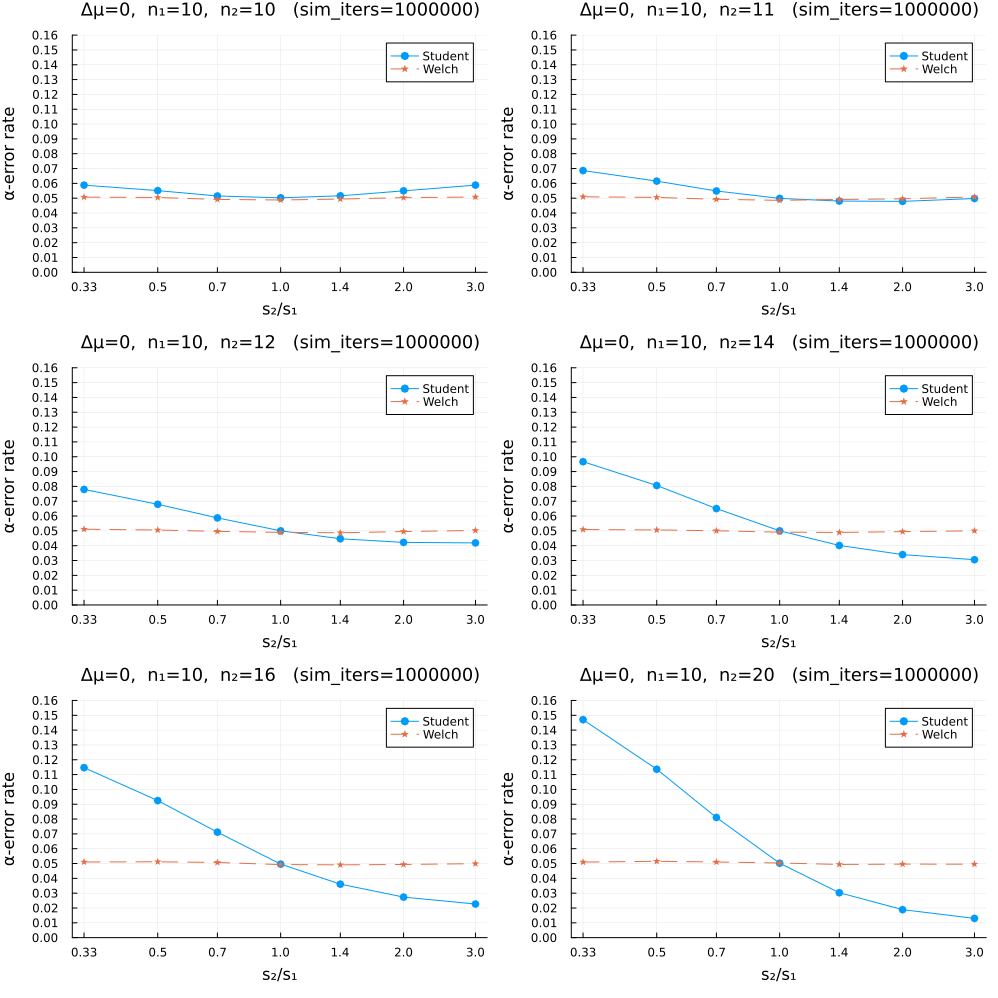

In [19]:
PP = []
for n in (10, 11, 12, 14, 16, 20)
    P = plot_powers(; Δμ=0, m=10, n, ylim=(0.00, 0.16), L=10^6, ytick=0:0.01:1)
    push!(PP, P)
end
plot(PP...; size=(1000, 1000), layout=(3, 2))

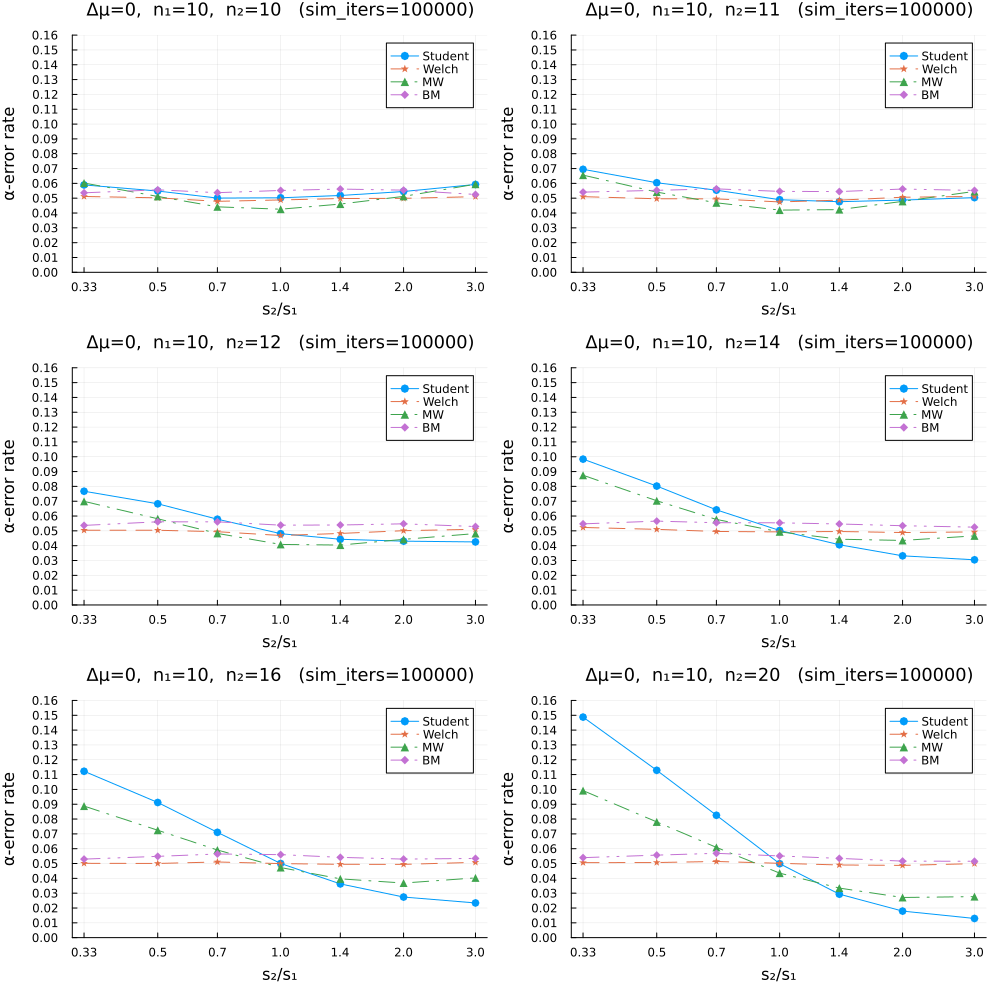

In [20]:
PP = []
for n in (10, 11, 12, 14, 16, 20)
    P = plot_powers(; Δμ=0, m=10, n, ylim=(0.00, 0.16), L=10^5, ytick=0:0.01:1, np=true)
    push!(PP, P)
end
plot(PP...; size=(1000, 1000), layout=(3, 2))

distx = Normal{Float64}(μ=0.0, σ=1.0)
disty = Normal{Float64}(μ=0.0, σ=1.0)


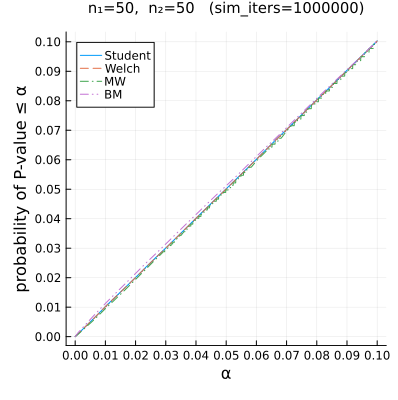

In [21]:
plot_α_error_rates(; distx=Normal(0, 1), disty=Normal(0, 1), m=50, n=50)

distx = Normal{Float64}(μ=0.0, σ=1.0)
disty = Normal{Float64}(μ=0.0, σ=4.0)


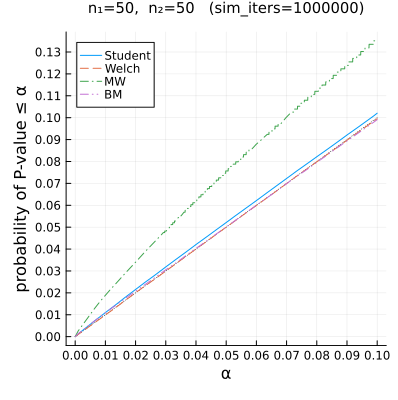

In [22]:
plot_α_error_rates(; distx=Normal(0, 1), disty=Normal(0, 4), m=50, n=50)

distx = Normal{Float64}(μ=0.0, σ=1.0)
disty = Normal{Float64}(μ=0.0, σ=4.0)


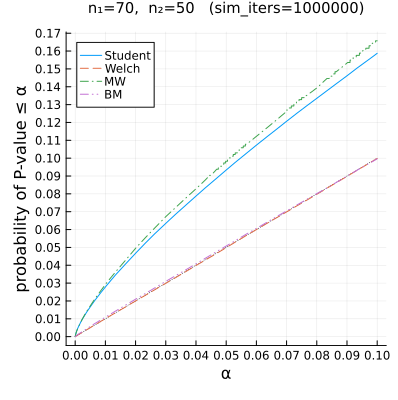

In [23]:
plot_α_error_rates(; distx=Normal(0, 1), disty=Normal(0, 4), m=70, n=50)

distx = Normal{Float64}(μ=0.0, σ=1.0)
disty = Normal{Float64}(μ=0.0, σ=4.0)


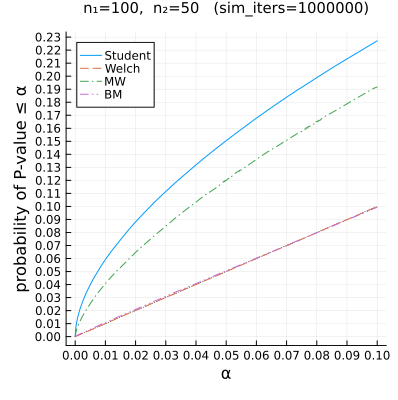

In [24]:
plot_α_error_rates(; distx=Normal(0, 1), disty=Normal(0, 4), m=100, n=50)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Exponential{Float64}(θ=1.0)
disty = Exponential{Float64}(θ=1.0)


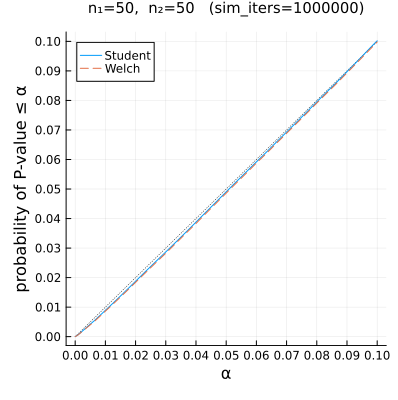

In [25]:
distx = Exponential()
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=50, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Exponential{Float64}(θ=1.0)
disty = Exponential{Float64}(θ=1.0)


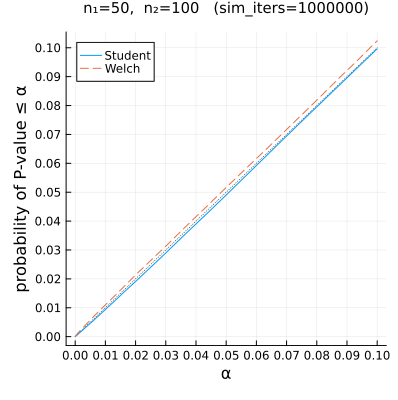

In [26]:
distx = Exponential()
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=100, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Exponential{Float64}(θ=1.0)
disty = Exponential{Float64}(θ=1.0)


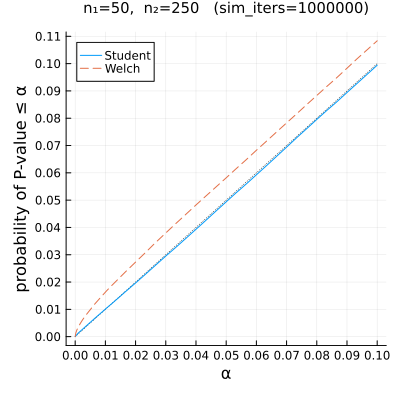

In [27]:
distx = Exponential()
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=250, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


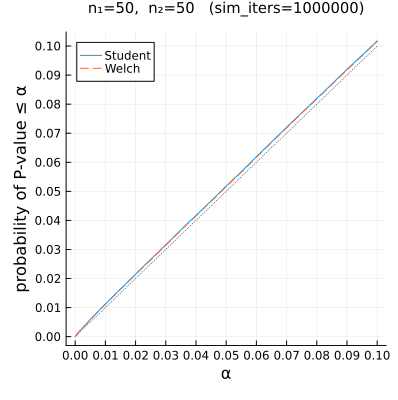

In [28]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=50, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


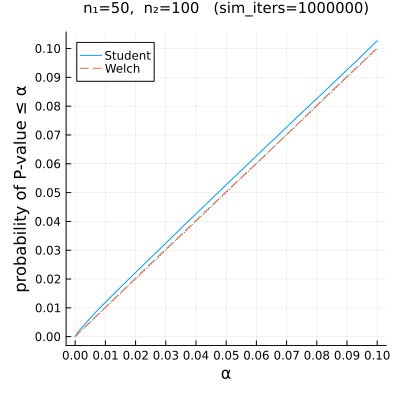

In [29]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=100, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


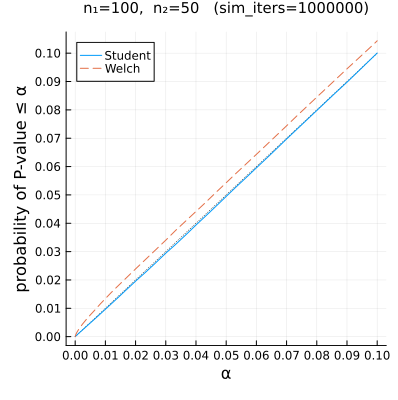

In [30]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=100, n=50, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


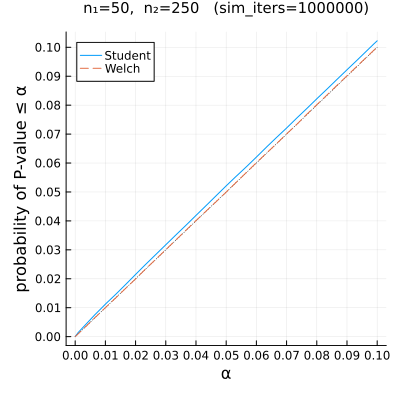

In [31]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=50, n=250, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


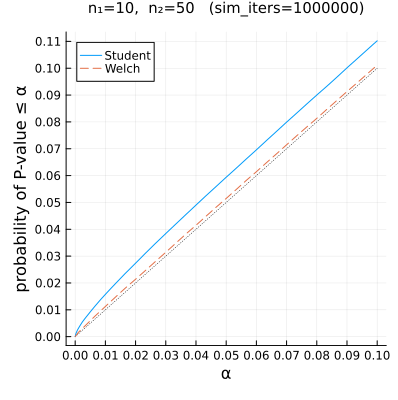

In [32]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=10, n=50, L=10^6, np=false)

mean(disty) - mean(distx) = 0.0
std(disty) / std(disty) = 1.0
distx = Normal{Float64}(μ=1.0, σ=1.0)
disty = Exponential{Float64}(θ=1.0)


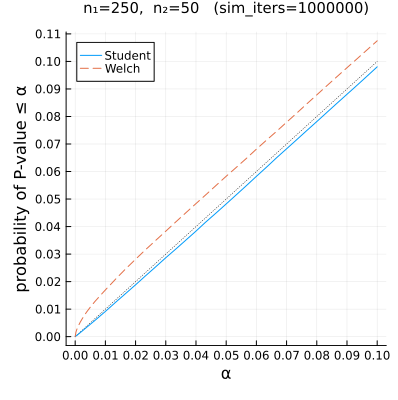

In [33]:
distx = Normal(1)
disty = Exponential()
@show mean(disty) - mean(distx)
@show std(disty) / std(disty)
plot_α_error_rates(; distx, disty, m=250, n=50, L=10^6, np=false)